# Diabetes Prediction - Machine Learning Project [Binary Classification]

## Chaimaa GOURRI SEGAME

## 1-Problem Definition:

**Question :** Can the medical and demographic characteristics of patients in this dataset help predict its recorded Outcome ? 

**Learning Type :** Supervised Learning  
**Machine Learning Task :** Binary Classification  
**Target Variable :** `Outcome`  
                - `1`= diabetes  
                - `0`=no diabetes  
**Dataset Source :** Dataset originally adapted from the National Institute of Diabetes and Digestive and Kidney Diseases (NIDDK).  
**Use :** Educational analysis only; the results are not clinically validated.


## 2-Data Understanding:

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import recall_score

RANDOM_STATE=42
DATA_PATH=Path("diabetes_dataset.csv")

if not DATA_PATH.exists():
    raise FileNotFoundError(f"Could not find {DATA_PATH}. Keep the CSV in the same folder as this notebook.")

In [2]:
df=pd.read_csv(DATA_PATH)
display(df.head())
print("Data set shape: ",df.shape)
df.info()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


Data set shape:  (768, 9)
<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


There are 768 observations  
There are 9 variables

In [3]:
display(df.describe().T)
class_counts=df["Outcome"].value_counts()
class_percentages=df["Outcome"].value_counts(normalize=True)*100
target_summary=pd.DataFrame({"Count": class_counts, "Percentages": class_percentages})
display(target_summary)

,count,mean,std,min,25%,50%,75%,max
Pregnancies,768.0,3.845052,3.369578,0.000,1.00000,3.0000,6.00000,17.00
Glucose,768.0,120.894531,31.972618,0.000,99.00000,117.0000,140.25000,199.00
BloodPressure,768.0,69.105469,19.355807,0.000,62.00000,72.0000,80.00000,122.00
SkinThickness,768.0,20.536458,15.952218,0.000,0.00000,23.0000,32.00000,99.00
Insulin,768.0,79.799479,115.244002,0.000,0.00000,30.5000,127.25000,846.00
BMI,768.0,31.992578,7.884160,0.000,27.30000,32.0000,36.60000,67.10
DiabetesPedigreeFunction,768.0,0.471876,0.331329,0.078,0.24375,0.3725,0.62625,2.42
Age,768.0,33.240885,11.760232,21.000,24.00000,29.0000,41.00000,81.00
Outcome,768.0,0.348958,0.476951,0.000,0.00000,0.0000,1.00000,1.00


,Count,Percentages
Outcome,,
0,500,65.104167
1,268,34.895833


- We can see that the "Outcome" variable exhibits a moderate imbalance, with approximately 65% ​​of observations belonging to class "0" and about 35% to class "1".

## 3-Exploratory Data Analysis (EDA)

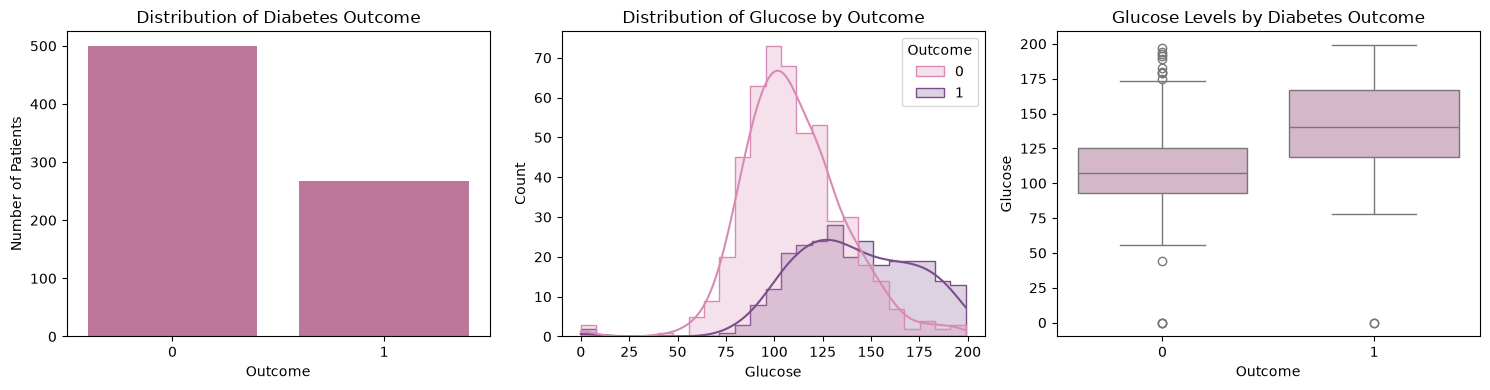

In [4]:
target="Outcome"
fig, axes=plt.subplots(1, 3, figsize=(15,4))

sns.countplot(data=df, x=target, ax=axes[0], color="#C66A9A")
axes[0].set(title="Distribution of Diabetes Outcome", xlabel="Outcome", ylabel="Number of Patients")

sns.histplot(data=df, x="Glucose", hue=target, bins=25, kde=True, element="step",palette={0: "#D98BB5", 1: "#7A4E8A"},ax=axes[1])
axes[1].set(title="Distribution of Glucose by Outcome", xlabel="Glucose")

sns.boxplot(data=df, x=target, y="Glucose", ax=axes[2], color="#D9B3CB")
axes[2].set(title="Glucose Levels by Diabetes Outcome", xlabel="Outcome", ylabel="Glucose")

plt.tight_layout()
plt.show()

- **Distribution of Diabetes Outcome:** 
The bar chart shows that class "0" contains approximately 500 observations while the class "1" contains around 268 observations.  
The bar chart therefore confirms a moderate class imbalance where the class "0" is the majority class at around 65%, whereas class "1" represents around 35%.  

- **Distribution of Glucose by Outcome:** The glucose values are mainly concentrated between approximately 80 and 140.  
The distribution is centered around 100-120 and extends until 200.  
For class 1, glucose values show a peak between 125 and 140. This suggests that glucose may be a useful feature for predicting the outcome.   
A few observations have a glucose value of 0 which may indicate missing or invalid values rather than actual measurements.

- **Glucose Levels by Diabetes Outcome:** The boxplot shows that observations in class "1" represent higher levels of glucose than observations in class "0".  
The median in class "1" is around 140 and in class "0" is around 105 which further suggests that the variable glucose is an important indicator/feature to predict diabetes.  
However, since the two classes overlap this variable alone is not enough to perfectly predict whether a patient has diabetes.  
Some outliers and zero values require further investigation.

We inspect zeroes before deciding how to handle them.

In [5]:
zeros_in_all_variables=["Pregnancies","Glucose", "BloodPressure","SkinThickness", "Insulin", "BMI","DiabetesPedigreeFunction","Age","Outcome"]
zero_counts=(df[zeros_in_all_variables]==0).sum()
zero_counts.rename("Zero Count").to_frame()


,Zero Count
Pregnancies,111
Glucose,5
BloodPressure,35
SkinThickness,227
Insulin,374
BMI,11
DiabetesPedigreeFunction,0
Age,0
Outcome,500


- Zero values were found in several variables, some zeros like in Pregnancies and Outcome seem to be valid while others like in Glucose, BMI, SkinThickness, BloodPressure and Insulin may rather be suspicious since their measurements are not expected to be zero.

### Replacing suspicious zeros with missing values:

In [6]:
zeros_as_missing=["Glucose", "BloodPressure","SkinThickness", "Insulin", "BMI"]
df_clean=df.copy()
df_clean[zeros_as_missing]=df_clean[zeros_as_missing].replace(0,np.nan)

### Correlation Analysis:

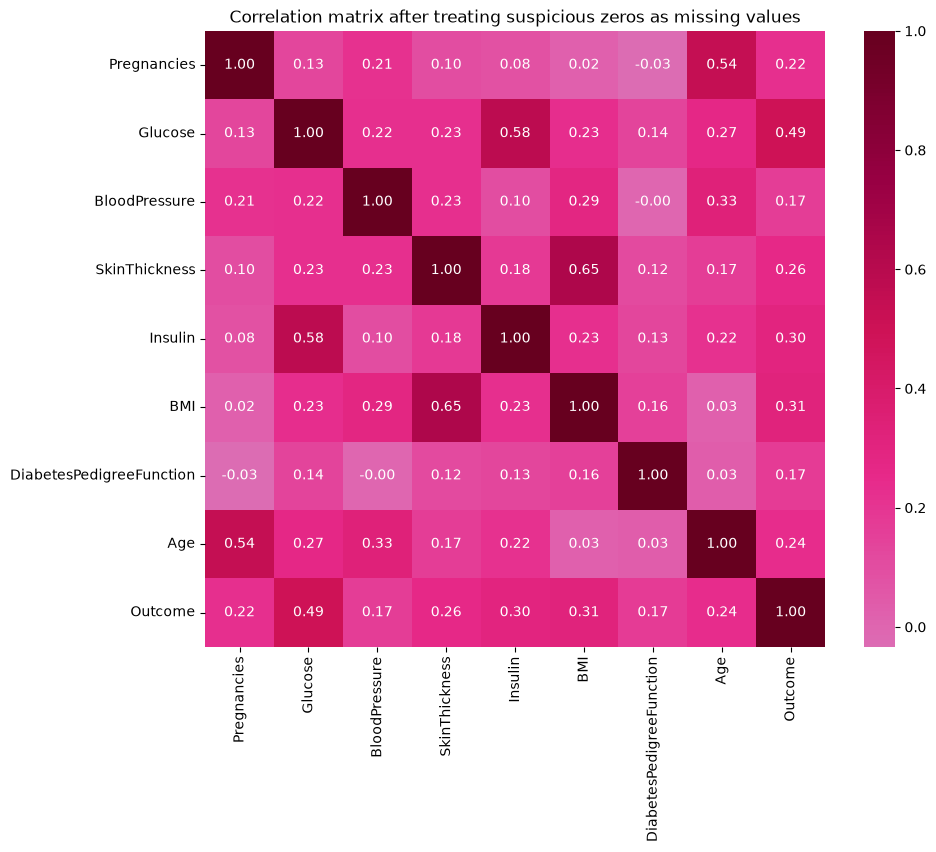

In [7]:
plt.figure(figsize=(10, 8))

sns.heatmap(df_clean.corr(numeric_only=True), annot=True, cmap="PuRd", fmt=".2f", center=0) 

plt.title("Correlation matrix after treating suspicious zeros as missing values")
plt.show()

- The Correlation Matrix shows no strong correlations between variables.  
- Most correlations are weak to moderate, with the strongest correlation being between Age and Pregnancies (0.54).  
- The target variable Outcome has the strongest correlation with the variables Glucose (0.47) followed by BMI (0.29) and age (0.24), however these correlations stay weak or moderate.  
- These variables may be useful to predict the variable Outcome, especially Glucose.  
- BMI and Age can still bring useful information, but their relationship with the target variable are weak, further analysis and model evaluation are needed to determine which variables are most useful for prediction.

## 4-Data Preprocessing:

### Split explanatory variables and target variables:


- X: Explanatory variables/the variables used for prediction (Pregnancies, Glucose, Blood Pressure, Skin Thickness, Insulin, BMI, DiabetesPedigreeFunction and Age).  
- Y: Target variable/the variable the model must predict (Outcome).

In [8]:
X=df_clean.drop(columns=target)
y=df_clean[target]

### Train/Test Split:

- We will split the data into:
    - 80%: training data (train).  
    - 20%: test data (test).  

- We will also keep a raw copy of both training data and test data (data with no imputation and scaling) that will be used later for the cross-validation section.

In [9]:
X_train, X_test, y_train, y_test=train_test_split(X,y, test_size=0.2, random_state=42, stratify=y)
#Raw copies of X_train and X_test
X_train_raw, X_test_raw=X_train.copy(), X_test.copy()
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:",y_train.shape)
print("y_test:",y_test.shape)

missing_summary=pd.DataFrame({"missing_count":X_train.isna().sum(),"missing_percent":(X_train.isna().mean()*100).round(1),})
display(missing_summary[missing_summary["missing_count"]>0])

X_train: (614, 8)
X_test: (154, 8)
y_train: (614,)
y_test: (154,)


,missing_count,missing_percent
Glucose,4,0.7
BloodPressure,23,3.7
SkinThickness,175,28.5
Insulin,290,47.2
BMI,9,1.5


### Imputation of missing values:

- Missing values ​​are imputed rather than removed, as some variables exhibit a significant number of missing values.  
- The median was chosen for imputation because it is less sensitive to extreme values.

In [10]:
imputer=SimpleImputer(strategy='median')

X_train=imputer.fit_transform(X_train)
X_test=imputer.transform(X_test)

### Standardization: 

In [11]:
scaler=StandardScaler()

X_train=scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [12]:
X_train.mean(axis=0)

array([-6.94341436e-17, -1.09937394e-16,  3.09560557e-16, -3.47170718e-17,
       -4.33963397e-18,  1.64906091e-16, -1.09937394e-16, -1.08490849e-16])

- mean practically equal to 0.

In [13]:
X_train.std(axis=0)

array([1., 1., 1., 1., 1., 1., 1., 1.])

- standard deviation (std) equal to 1.

The data was prepared for modeling:  
- Suspicious zeros in selected measurement variables were treated as missing values.  
- Missing values were imputed using the median.
- Variables were standardized.

## 5-Machine Learning: Model Training 

### 5.1) Logistic Regression:  

This is the relatively simple linear baseline among the three predictive models.

In [14]:
logistic_model=LogisticRegression(random_state=42)

logistic_model.fit(X_train , y_train)
y_pred_logistic=logistic_model.predict(X_test)

### 5.2) Decision Tree:

A decision tree learns feature-based rules. The default tree can fit the training data very closely, so we will compare its training and test performance.

In [15]:
tree_model=DecisionTreeClassifier(random_state=42)

tree_model.fit(X_train, y_train)
y_pred_tree=tree_model.predict(X_test)

### 5.3) Random Forest:


A Random Forest combines multiple decision trees. It provides a useful comparison with a single tree.

In [16]:
model_forest=RandomForestClassifier(random_state=42)

model_forest.fit(X_train, y_train)
y_pred_forest=model_forest.predict(X_test)

## 6-Evaluation and Model Comparison:

Creating a table to visualize the comparison of different accuracies and classification metrics

In [17]:
majority_class=y_train.mode().iloc[0]
baseline_predictions=np.full(len(y_test), majority_class)

train_accuracy_baseline=(y_train==majority_class).mean()
train_accuracy_logistic=accuracy_score(y_train, logistic_model.predict(X_train))
train_accuracy_tree=accuracy_score(y_train, tree_model.predict(X_train))
train_accuracy_forest=accuracy_score(y_train, model_forest.predict(X_train))


models={"Logistic Regression": logistic_model, 
        "Decision Tree": tree_model, 
        "Random Forest": model_forest,
        }

predictions={"Majority Class Baseline": baseline_predictions, 
             "Logistic Regression": y_pred_logistic, 
             "Decision Tree": y_pred_tree, 
             "Random Forest": y_pred_forest, 
             }

train_accuracies={"Majority Class Baseline": train_accuracy_baseline,
                  "Logistic Regression": train_accuracy_logistic, 
                  "Decision Tree": train_accuracy_tree, 
                  "Random Forest": train_accuracy_forest
                  }

rows=[]
for name, y_pred in predictions.items():
    report=classification_report(y_test, y_pred, output_dict=True, zero_division=0)
    train_accuracy=train_accuracies[name]
    test_accuracy=accuracy_score(y_test, y_pred)
    rows. append({
        "Model": name,
        "Training accuracy":train_accuracy,
        "Test accuracy":test_accuracy,
        "Recall class 0": report["0"]["recall"],
        "Precision class 1": report["1"]["precision"],
        "Recall class 1": report["1"]["recall"],
        "F1 class 1": report["1"]["f1-score"],
        "Train-test gap (pp)": (train_accuracy - test_accuracy) * 100,
    })

#pd.DataFrame(rows):transformer la liste des lignes en tableau;
#set_index("Model"): met le nom du modèle comme éttiquette de ligne;
comparison = pd.DataFrame(rows).set_index("Model")
percentage_columns=["Training accuracy", "Test accuracy", "Recall class 0", "Precision class 1", "Recall class 1", "F1 class 1"]

comparison[percentage_columns]*=100
comparison = comparison.sort_values("Test accuracy", ascending=False).round(1)

display(comparison)

,Training accuracy,Test accuracy,Recall class 0,Precision class 1,Recall class 1,F1 class 1,Train-test gap (pp)
Model,,,,,,,
Random Forest,100.0,77.3,86.0,70.2,61.1,65.3,22.7
Logistic Regression,79.6,70.8,82.0,60.0,50.0,54.5,8.9
Decision Tree,100.0,68.2,79.0,55.3,48.1,51.5,31.8
Majority Class Baseline,65.1,64.9,100.0,0.0,0.0,0.0,0.2


- The Majority-Class Baseline shows how much accuracy is obtained by always predicting the most frequent class (class 0).  

- The Logistic regression model achieved an accuracy of approximately 71% on the test set. Its performence differed between the two classes; it correctly identified 82% of class 0 observations, in comparison to 50% for class 1.

- The Decision Tree achieved an accuracy of 68% on the test set. It correctly classified 79% of class 0 observations and 48% of class 1 observations. Like the logistic regression model, it performed better on class 0 than on class 1. Its recall was slightly lower than the logistic regression model’s for both classes: 79% versus 82% for class 0, and 48% versus 50% for class 1.

- For Random Forest, we can see that 86% of class 0 observations and 61% of class 1 observations were correctly classified. Like the other two models, the Random Forest performs better on class 0 than on class 1. However, it has a higher overall accuracy than the other two models.

- We can also see an overfitting for both Decision Tree and Random Forest models, where they both perform better in training set in comprison to the test set.

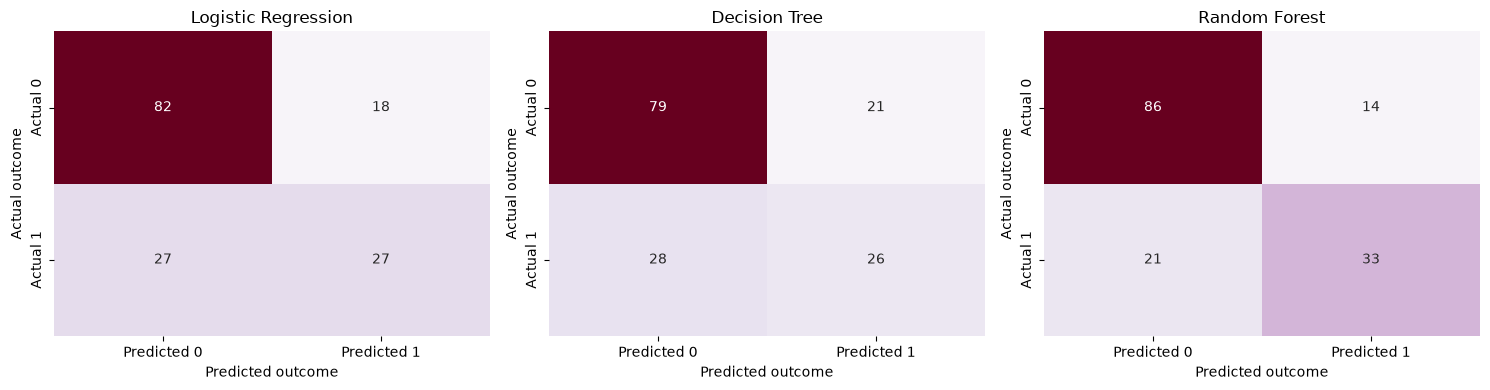

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax,name in zip(axes, models):
    y_pred=predictions[name]
    cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="PuRd", cbar=False, ax=ax,
        xticklabels=["Predicted 0", "Predicted 1"],
        yticklabels=["Actual 0", "Actual 1"],
    )
    ax.set_title(name)
    ax.set_xlabel("Predicted outcome")
    ax.set_ylabel("Actual outcome")

plt.tight_layout()
plt.show()

- All three models classified class 0 better than class 1, but Random Forest performed better at classifying class 1 than the other two models.


## 7-Cross-validation: more reliable comparison:

So far we've only done one train/test split and with this number of observations (the test set has only 154 patients, 54 of them have diabetes), a cross-validation might be more reliable.

The train observations will be split into 5 folds, the model will be trained on 4 folds and validated on the remaining one. This will be repeated 5 times. Then we will calculate the mean and standard deviation and evaluate the variation between the accuracies.

We will do this for each metric; accuracy, recall and ROC-AUC.

For each fold we will use a Pipeline function where we will be imputing and scaling values in the raw data so that the validation fold would not be influenced.

In [19]:
cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
#This contains the rule for 5-fold partitioning

#We also create a pipeline to keep the steps compact and prevent data leakage.
#This pipeline consists of: imputation, followed by standardization, and then model training.
def make_pipe(model):
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", model),
    ])

#we create a dictionary with fresh models (starting from scratch, so as not to use models that have already been trained on the data)
cv_models={
    "Majority Class Baseline": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": LogisticRegression(random_state=RANDOM_STATE),
    "Decision Tree": DecisionTreeClassifier(random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(random_state=RANDOM_STATE),
}

#we set up a table to be filled in for visualization purposes, and within this table, cross-validation is performed
rows=[]
for name, model in cv_models.items():
    res=cross_validate(make_pipe(model), X_train_raw, y_train, cv=cv, scoring=["accuracy", "recall", "roc_auc"])
    rows.append({
        "Model": name,
        "Accuracy (mean)": res["test_accuracy"].mean(),
        "Accuracy (std)": res["test_accuracy"].std(),
        "Recall class 1 (mean)": res["test_recall"].mean(),
        "ROC-AUC (mean)": res["test_roc_auc"].mean(),
    })

#round(3): round to three decimal places;
cv_results=pd.DataFrame(rows).set_index("Model").round(3)
display(cv_results)

,Accuracy (mean),Accuracy (std),Recall class 1 (mean),ROC-AUC (mean)
Model,,,,
Majority Class Baseline,0.651,0.002,0.000,0.500
Logistic Regression,0.788,0.019,0.575,0.843
Decision Tree,0.673,0.019,0.580,0.651
Random Forest,0.762,0.016,0.580,0.816


- The baseline model shows an average accuracy of 65.1%, with a standard deviation of 0.2% indicating very little variation, as the accuracy remains nearly constant across each fold. The recall for class 1 averages zero; because the baseline always predicts class 0 , it fails to identify any patients who are diabetic (class 1). The ROC-AUC averages 50%, which is equivalent to random chance, meaning the baseline is unable to distinguish between a diabetic individual and a healthy one.

- Following this cross-validation, we observe significant changes that lead us to revise some of the conclusions drawn from the evaluation in Section 6. Logistic regression now performs best, yielding the highest accuracy and ROC-AUC among the three models, while the performance of the decision tree and random forest has slightly decreased. However, all three models show a recall of approximately 58% for class 1, meaning they still fail to correctly identify about 4 out of every 10 diabetic patients.

## 8-Reducing Overfitting:

###  Decision Tree:

- As shown in the evaluation in Section 6, the decision tree exhibits overfitting: it achieves 100% accuracy on the training data compared to 68.2% on the test data, a gap of 31.8 percentage points. To reduce this overfitting, we will define parameters that limit the maximum depth of the tree (the number of questions asked) and set a minimum number of patients per leaf node. We will then test various combinations using cross-validation with the raw data, so that imputation and scaling are refitted in each fold and subsequently evaluate the performance of the best-performing configuration.

In [20]:
#grid where we'll set the parameters for the decision tree
param_grid={
    "model__max_depth":[2,3,4,5,6, None], 
    "model__min_samples_leaf":[1,5,10,20]}

#we also impute+scale+model+cross-validate all with the new parameters
grid=GridSearchCV(make_pipe(DecisionTreeClassifier(random_state=RANDOM_STATE)),
                  param_grid, cv=cv, scoring="roc_auc")

#fit=train
grid.fit(X_train_raw, y_train)

#meilleurs valeurs
print("Best parameters:", grid.best_params_)
#score en validation croisée
print("Best cross-validated ROC-AUC:", round(grid.best_score_, 3))

Best parameters: {'model__max_depth': 4, 'model__min_samples_leaf': 1}
Best cross-validated ROC-AUC: 0.79


### Random Forest :

- The random forest also reaches 100% training accuracy, so it also overfits.  

- For this model the same parameters and approach we did for the tuned decision tree will be applied.

In [21]:
param_grid_rf={
    "model__max_depth":[2, 3, 4, 5, 6, None],
    "model__min_samples_leaf":[1, 5, 10, 20],
}

grid_rf=GridSearchCV(make_pipe(RandomForestClassifier(random_state=RANDOM_STATE)),
                               param_grid_rf, cv=cv, scoring="roc_auc")

grid_rf.fit(X_train_raw, y_train)

print("Best parameters:", grid_rf.best_params_)
print("Best cross-validated ROC-AUC:", round(grid_rf.best_score_, 3))

Best parameters: {'model__max_depth': 4, 'model__min_samples_leaf': 5}
Best cross-validated ROC-AUC: 0.842


### Comparison Table:

In [22]:
#we define the tuned tree (arbre limité/régularisé) to the best Pipeline that has the best combination
tuned_tree=grid.best_estimator_

#same for random forest;
tuned_forest=grid_rf.best_estimator_


final_model={
    "Decision Tree (default)": make_pipe(DecisionTreeClassifier(random_state=RANDOM_STATE)),
    "Decision Tree (tuned)": tuned_tree,
    "Random Forest (default)": make_pipe(RandomForestClassifier(random_state=RANDOM_STATE)),
    "Random Forest (tuned)": tuned_forest,
    "Logistic Regression": make_pipe(LogisticRegression(random_state=RANDOM_STATE)),
    }

rows=[]
for name, pipe in final_model.items():
    pipe.fit(X_train_raw, y_train)
    train_acc=accuracy_score(y_train, pipe.predict(X_train_raw))
    test_acc=accuracy_score(y_test, pipe.predict(X_test_raw))
    rows.append({"Model": name,
                 "Training accuracy": train_acc,
                 "Test accuracy": test_acc,
                 "Train-Test gap (pp)": (train_acc-test_acc)*100,
                 "Recall class 1 (test)": recall_score(y_test,pipe.predict(X_test_raw))})

final_results=pd.DataFrame(rows).set_index("Model").round(3)
display(final_results)

,Training accuracy,Test accuracy,Train-Test gap (pp),Recall class 1 (test)
Model,,,,
Decision Tree (default),1.000,0.682,31.818,0.481
Decision Tree (tuned),0.795,0.786,0.907,0.685
Random Forest (default),1.000,0.773,22.727,0.611
Random Forest (tuned),0.821,0.734,8.708,0.481
Logistic Regression,0.796,0.708,8.862,0.500


- After addressing the overfitting, we can see that the performance gap between the training data and the test data for the decision tree has narrowed; in other words, overfitting has been reduced. We also observe an increase in recall. Consequently, this tuned decision tree performs better than the original default decision tree, bringing it close to the performance of the logistic regression model. However, it cannot be considered the best-performing model, as the logistic regression model following cross-validation demonstrated better metrics.

- For the Random Forest, we can see that the gap between training accuracy and test accuracy has also narrowed, though it remains significant. Notably, the recall has also decreased compared to the default Random Forest model. This could be due to the small number of patients with diabetes (only 54 in the test set). The cross-validation ROC-AUC is 0.84, indicating that the results are not due to chance and represent a reasonably good classification. It should be noted, however, that this score was achieved using best parameters found by search (max_depth=4 and min_samples_leaf=5).

## 9- Conclusions and Limitations:

**Conclusions:**
- Patient characteristics can predict diabetes with an accuracy of about 76-79% in cross-validation, versus 65% for the baseline.
- Logistic Regression is slightly ahead in cross-validation, but there is no clear winner between the three models.
- Cross-validation changed the conclusion of section 6, where the Random Forest seemed best: a single split was not enough.
- The Decision Tree and Random Forest overfit; tuning narrowed the train-test gap for both.
- Recall for class 1 is about 58% in cross-validation: about 4 diabetic patients out of 10 are missed, which is serious in a medical context.

**Limitations:**
- Small dataset (the test set has only 154 patients, 54 of them with diabetes).
- Insulin (49%) and SkinThickness (about 30%) had many missing values, imputed with the median.
- This project is educational and not intended for medical use.